# Prototype: weather sequences as branches of the scenario tree

This notebook prototypes the approach described in
[`weather_sequences_approach.md`](weather_sequences_approach.md):

* candidate **multi-year weather sequences** are cut from the weather record as overlapping
  windows;
* tsam selects **5 representative sequences**, one of them the extreme sequence; their
  probabilities are the (mildly recency-weighted) cluster weights, or uniform;
* **every representative sequence becomes a node of the tree**: at the start of stage 2 the tree
  branches into one node per sequence, and every investment period of a node holds **one**
  weather year, the corresponding year of the node's sequence;
* the tree branches **only on weather**; demand follows one structural path.

It runs with the **committed** version of the MSSP module. One workaround: the first-stage
decisions of *all* first-stage investment periods are read from the `commis_*` variables directly,
because the module's `firstStageDecisions()` only returns the first investment period.

Setup: 2 regions, 6 yearly investment periods (2030–2035), 2 stages of 3 investment periods,
**sequences of 3 years** (= investment periods per stage; 5-year sequences work the same way),
5 stage-2 nodes, typical days. Lead times are not part of this branch yet.

> **All weather data in this notebook are SYNTHETIC**, with the structure of SECURES-Energy data
> (hourly temperature and renewable capacity factors per region and weather year).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import fine as fn
import fine.expansionModules.multiStageStochasticProgram as mssp

## 1. Synthetic weather years

Twenty candidate weather years (labelled 1991 to 2010), each with hourly temperature, wind and
PV capacity factors for both regions. Daily weather anomalies are persistent, cold winter spells
tend to be calm (Dunkelflaute), and both regions share the large-scale weather with some regional
noise.

In [2]:
import time

import numpy as np
import tsam

HOURS = 8760
WEATHER_REGIONS = ["north", "south"]
CANDIDATE_YEARS = list(range(1991, 2011))  # 20 synthetic "historical" weather years

day = np.arange(HOURS) // 24
hour = np.arange(HOURS) % 24
days = HOURS // 24
season = np.cos(2 * np.pi * (day - 15) / 365)  # +1 in mid-January


def ar1(rng, phi, sigma, n):
    """Persistent random series: every value depends on the previous one."""
    x = np.zeros(n)
    for i in range(1, n):
        x[i] = phi * x[i - 1] + rng.normal(0, sigma)
    return x


# One SYNTHETIC weather year per candidate year: temperature, wind and PV per region.
weatherYears = {}
for year in CANDIDATE_YEARS:
    rng = np.random.default_rng(year)
    anomaly = ar1(rng, 0.85, 1.6, days) + rng.normal(0, 0.8)  # daily temperature anomaly, K
    calm = 0.45 * anomaly / anomaly.std() + np.sqrt(1 - 0.45**2) * ar1(rng, 0.8, 1.0, days)
    calm /= calm.std()  # cold days tend to be calm days
    cloud = np.clip(0.65 + 0.25 * ar1(rng, 0.6, 0.6, days), 0.15, 1.0)

    data = {}
    for region, windBase, pvScale, regionalSeed in [("north", 0.36, 0.85, 1), ("south", 0.26, 1.10, 2)]:
        regional = np.random.default_rng(year * 10 + regionalSeed)
        temperature = (
            10
            - 9 * season
            + anomaly[day]
            + 3 * np.sin(2 * np.pi * (hour - 9) / 24)
            + regional.normal(0, 0.5, HOURS)
        )
        wind = windBase + 0.08 * season + 0.15 * calm[day] + regional.normal(0, 0.04, HOURS)
        daylight = np.clip(np.sin(np.pi * (hour - 6 + 2 * season) / (12 - 4 * season)), 0, None)
        cloudiness = np.clip(cloud[day] + regional.normal(0, 0.05, days)[day], 0.1, 1)
        pv = pvScale * 0.70 * (0.55 - 0.45 * season) * daylight * cloudiness
        data[f"temperature_{region}"] = temperature
        data[f"wind_{region}"] = np.clip(wind, 0.0, 0.95)
        data[f"pv_{region}"] = np.clip(pv, 0.0, 0.9)
    weatherYears[year] = pd.DataFrame(data)

# Weather-driven demand profile: heating degree hours drive the heat-pump load.
heatProfiles = {
    year: {
        region: np.clip(15.0 - w[f"temperature_{region}"].to_numpy(), 0, None)
        for region in WEATHER_REGIONS
    }
    for year, w in weatherYears.items()
}
# Normalized so that the heat-pump parameter below is the average load in an average year.
heatNorm = {
    region: np.mean([heatProfiles[y][region].mean() for y in CANDIDATE_YEARS])
    for region in WEATHER_REGIONS
}

pd.DataFrame(
    {
        year: {
            "mean wind CF north": w["wind_north"].mean(),
            "mean PV CF south": w["pv_south"].mean(),
            "heating degree hours / mean": heatProfiles[year]["north"].mean() / heatNorm["north"],
        }
        for year, w in weatherYears.items()
    }
).T.round(3)

,mean wind CF north,mean PV CF south,heating degree hours / mean
1991,0.360,0.098,0.933
1992,0.328,0.097,1.036
1993,0.385,0.096,0.987
1994,0.383,0.105,0.900
1995,0.351,0.107,0.932
1996,0.348,0.104,1.030
1997,0.347,0.096,1.017
1998,0.366,0.096,0.977
1999,0.384,0.100,1.054
2000,0.335,0.095,1.037


## 2. Demand built from parts

The electricity demand in an investment period, for weather year *w*, is

$$\text{demand}(ip, w, t) = \text{base}(ip) \cdot \text{shape}(t) + \text{HP}(ip) \cdot \text{heat}_w(t) + \text{DC}(ip) + \text{EV}(ip) \cdot \text{ev}(t)$$

* `base`, `HP` (heat pumps), `DC` (data centres) and `EV` (electric vehicles) are **structural**
  parameters in GW of average load. They follow **one** path over 2030–2035 (no structural
  branching);
* `heat_w(t)` is the **weather-driven** heat-pump profile of weather year *w*;
* `shape(t)` and `ev(t)` are weather-independent daily and weekly patterns.

So the demand of a node differs from that of another node only through the weather years of its
sequence.

In [3]:
_hour = np.arange(HOURS) % 24
_weekday = (np.arange(HOURS) // 24) % 7
BASE_SHAPE = 1 + 0.18 * np.sin(2 * np.pi * (_hour - 7) / 24) - 0.08 * (_weekday >= 5)
BASE_SHAPE /= BASE_SHAPE.mean()
EV_SHAPE = 0.2 + np.exp(-0.5 * (((_hour - 20 + 12) % 24) - 12) ** 2 / 9)  # evening peak
EV_SHAPE /= EV_SHAPE.mean()


def demandFromParts(structure, weatherYear):
    """Hourly electricity demand (GW = GWh per hourly step) for one structure and weather year."""
    return pd.DataFrame(
        {
            region: structure["base"][region] * BASE_SHAPE
            + structure["heatPump"][region]
            * heatProfiles[weatherYear][region]
            / heatNorm[region]
            + structure["dataCentre"][region]
            + structure["electricVehicles"][region] * EV_SHAPE
            for region in WEATHER_REGIONS
        }
    )


def structure(heatPump, dataCentre, electricVehicles):
    return {
        "base": {"north": 30.0, "south": 25.0},
        "heatPump": dict(zip(WEATHER_REGIONS, heatPump)),
        "dataCentre": dict(zip(WEATHER_REGIONS, dataCentre)),
        "electricVehicles": dict(zip(WEATHER_REGIONS, electricVehicles)),
    }


# Structural parameters per investment period (average GW per region). One path only: the
# tree branches on weather, not on structure.
STRUCTURE = {
    2030: structure((5.0, 3.5), (1.5, 1.0), (2.5, 2.0)),
    2031: structure((5.5, 4.0), (2.0, 1.2), (3.0, 2.4)),
    2032: structure((6.0, 4.5), (2.5, 1.4), (3.5, 2.8)),
    2033: structure((6.8, 5.1), (3.0, 1.8), (4.0, 3.2)),
    2034: structure((7.5, 5.6), (3.5, 2.0), (4.4, 3.5)),
    2035: structure((8.2, 6.1), (4.0, 2.2), (4.8, 3.8)),
}
WEATHER_STAGES = [[0, 1, 2], [3, 4, 5]]  # stage 1: 2030-2032 | stage 2: 2033-2035
WEATHER_IP_YEARS = [2030, 2031, 2032, 2033, 2034, 2035]
SEQUENCE_LENGTH = len(WEATHER_STAGES[0])  # 3 here; 5-year sequences work the same way

pd.DataFrame(
    {
        year: {
            "mean demand [GW]": demandFromParts(params, 2002).sum(axis=1).mean(),
            "peak demand, weather year 2002 [GW]": demandFromParts(params, 2002).sum(axis=1).max(),
        }
        for year, params in STRUCTURE.items()
    }
).T.round(1)

,mean demand [GW],"peak demand, weather year 2002 [GW]"
2030,71.6,97.2
2031,74.3,103.3
2032,77.1,109.3
2033,80.5,116.9
2034,83.2,123.2
2035,86.0,129.5


### How realistic is the synthetic weather?

Three weather years are shown: the coldest, the median and the mildest by heating demand. The
first figure shows daily means of demand (with the 2030 structure), wind and PV capacity factors,
and one hourly winter week. The second compares the synthetic data with the **real hourly data**
of one weather year that is already in the repository (`examples/data/multiRegion`, region
`cluster_6`): duration curves and a few indicators. FINE's plotting functions (`plotOperation`,
`plotOperationColorMap`, …) only plot optimization results, so the input data are plotted with
matplotlib.

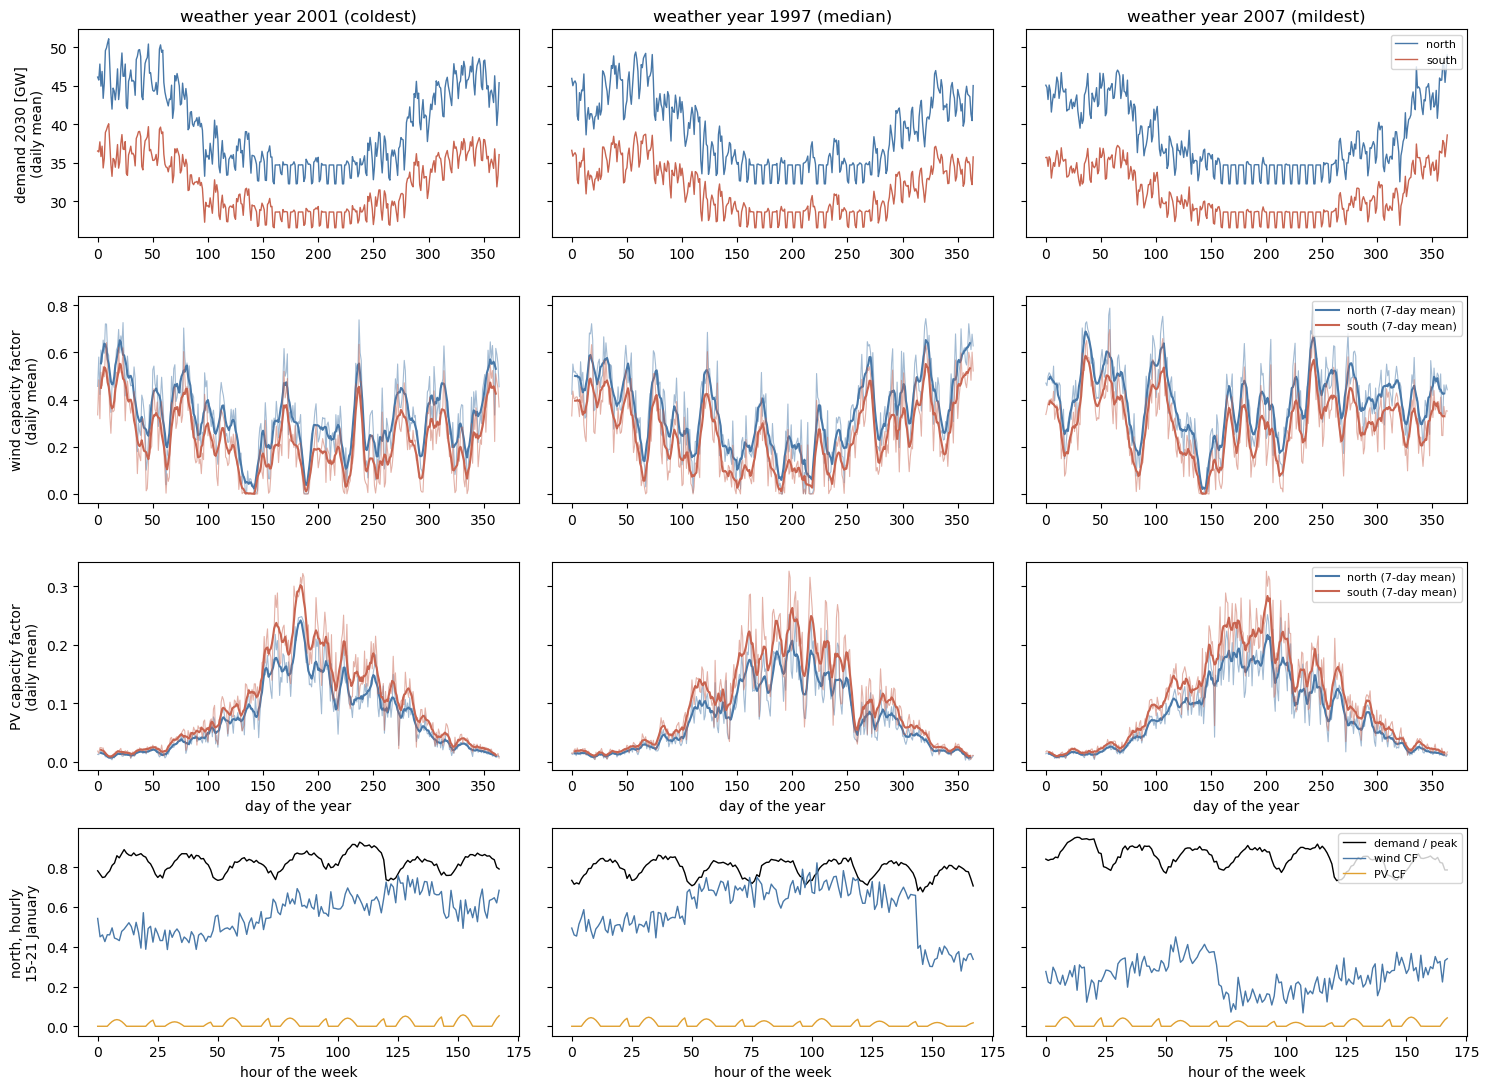

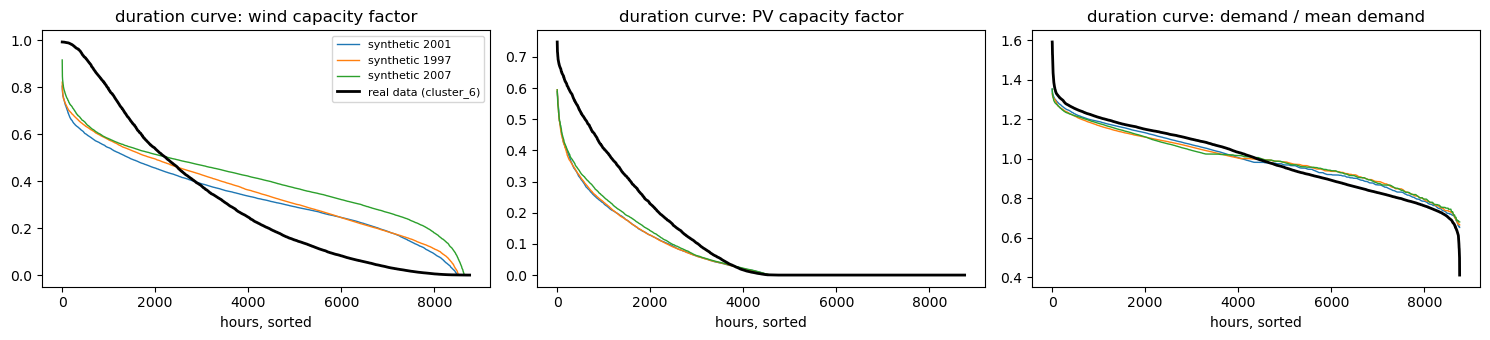

,synthetic 2001,synthetic 1997,synthetic 2007,real data
mean wind CF,0.327,0.347,0.398,0.310
hours with wind CF < 0.1 [%],9.692,7.283,3.744,34.954
longest spell of days with wind CF < 0.15,15.000,7.000,11.000,8.000
mean PV CF,0.074,0.074,0.079,0.122
hours with PV = 0 [%],47.979,48.025,47.991,48.527
peak / mean demand,1.354,1.330,1.354,1.592


In [4]:
# Three weather years: the coldest, the median and the mildest by heating demand (north)
byHeat = sorted(CANDIDATE_YEARS, key=lambda y: heatProfiles[y]["north"].mean())
shownYears = [byHeat[-1], byHeat[len(byHeat) // 2], byHeat[0]]
labelOfYear = dict(zip(shownYears, ["coldest", "median", "mildest"]))
colors = {"north": "#4878A8", "south": "#C86450"}
dayAxis = np.arange(365)

fig, axes = plt.subplots(4, 3, figsize=(15, 11), sharey="row")
for col, year in enumerate(shownYears):
    demand2030 = demandFromParts(STRUCTURE[2030], year)
    for region in WEATHER_REGIONS:
        axes[0, col].plot(dayAxis, demand2030[region].to_numpy().reshape(365, 24).mean(axis=1),
                          color=colors[region], lw=1, label=region)
        for row, kind in [(1, "wind"), (2, "pv")]:
            daily = weatherYears[year][f"{kind}_{region}"].to_numpy().reshape(365, 24).mean(axis=1)
            axes[row, col].plot(dayAxis, daily, color=colors[region], lw=0.8, alpha=0.5)
            axes[row, col].plot(dayAxis, pd.Series(daily).rolling(7, center=True).mean(),
                                color=colors[region], lw=1.5, label=f"{region} (7-day mean)")
    # one hourly winter week (north)
    week = slice(24 * 14, 24 * 21)
    axes[3, col].plot(demand2030["north"].to_numpy()[week] / demand2030["north"].max(), color="k", lw=1,
                      label="demand / peak")
    axes[3, col].plot(weatherYears[year]["wind_north"].to_numpy()[week], color="#4878A8", lw=1, label="wind CF")
    axes[3, col].plot(weatherYears[year]["pv_north"].to_numpy()[week], color="#E0A030", lw=1, label="PV CF")
    axes[0, col].set_title(f"weather year {year} ({labelOfYear[year]})")
axes[0, 0].set_ylabel("demand 2030 [GW]\n(daily mean)")
axes[1, 0].set_ylabel("wind capacity factor\n(daily mean)")
axes[2, 0].set_ylabel("PV capacity factor\n(daily mean)")
axes[3, 0].set_ylabel("north, hourly\n15-21 January")
for col in range(3):
    axes[2, col].set_xlabel("day of the year")
    axes[3, col].set_xlabel("hour of the week")
for row in range(4):
    axes[row, 2].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

# Comparison with the real hourly data of one weather year in the repository
dataPath = Path("..") / "data" / "multiRegion" / "SpatialData"
real = {
    "wind": pd.read_excel(dataPath / "Wind" / "maxOperationRateOnshore_el.xlsx", index_col=0)["cluster_6"].to_numpy(),
    "pv": pd.read_excel(dataPath / "PV" / "maxOperationRatePV_el.xlsx", index_col=0)["cluster_6"].to_numpy(),
    "demand": pd.read_excel(dataPath / "Demands" / "electricityDemand_GWh_el.xlsx", index_col=0)["cluster_6"].to_numpy(),
}
synthetic = {
    year: {
        "wind": weatherYears[year]["wind_north"].to_numpy(),
        "pv": weatherYears[year]["pv_north"].to_numpy(),
        "demand": demandFromParts(STRUCTURE[2030], year)["north"].to_numpy(),
    }
    for year in shownYears
}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (kind, title) in zip(axes, [("wind", "wind capacity factor"), ("pv", "PV capacity factor"),
                                    ("demand", "demand / mean demand")]):
    for year in shownYears:
        values = synthetic[year][kind] / (synthetic[year][kind].mean() if kind == "demand" else 1)
        ax.plot(np.sort(values)[::-1], lw=1, label=f"synthetic {year}")
    values = real[kind] / (real[kind].mean() if kind == "demand" else 1)
    ax.plot(np.sort(values)[::-1], color="k", lw=2, label="real data (cluster_6)")
    ax.set_title(f"duration curve: {title}")
    ax.set_xlabel("hours, sorted")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Indicators: mean capacity factors, low-wind hours, the longest calm spell, demand peak
indicators = {}
for name, data in [*((f"synthetic {y}", synthetic[y]) for y in shownYears), ("real data", real)]:
    dailyWind = data["wind"].reshape(365, 24).mean(axis=1)
    longest, current = 0, 0
    for calm in dailyWind < 0.15:
        current = current + 1 if calm else 0
        longest = max(longest, current)
    indicators[name] = {
        "mean wind CF": data["wind"].mean(),
        "hours with wind CF < 0.1 [%]": 100 * (data["wind"] < 0.1).mean(),
        "longest spell of days with wind CF < 0.15": longest,
        "mean PV CF": data["pv"].mean(),
        "hours with PV = 0 [%]": 100 * (data["pv"] < 1e-3).mean(),
        "peak / mean demand": data["demand"].max() / data["demand"].mean(),
    }
pd.DataFrame(indicators).round(3)

**What the figures show.** The synthetic weather has the right seasonal shape and the right
night share of PV (48 % of hours without PV), and it has multi-day calm periods (longest spell
with daily wind CF < 0.15: 7–15 days, real 8). But compared with the real year it is too benign:

| | synthetic (3 years) | real |
|---|---|---|
| mean wind CF | 0.33–0.40 | 0.31 |
| hours with wind CF < 0.1 | 4–10 % | 35 % |
| mean PV CF | 0.074–0.079 | 0.122 |
| peak / mean demand | 1.33–1.35 | 1.59 |

* **Wind:** the duration curve is much flatter. There are too few hours with almost no wind and
  too few very windy hours; calm periods have *low* wind rather than *no* wind. The daily series
  also oscillate in an unrealistically regular way over a few weeks.
* **PV:** too low on average and at the top of the duration curve.
* **Demand:** the peaks are too weak, and the weekday pattern is more regular than in reality.

All three point in the same direction: the synthetic data **underestimate scarcity**, i.e. the
need for firm capacity and storage in dark and calm periods. That is enough to test the method,
but the numbers in this notebook (capacities, costs, unserved demand) should not be read as
results. The real data here are a single year of one region, so they cannot replace the
multi-year record; for that, real multi-year data such as the PECD (planned for the
rolling-horizon application anyway) are needed. The rest of the notebook is built for that: mainly
`weatherYears` (hourly wind and PV capacity factors per region and weather year)
and `heatProfiles` would have to be replaced.

## 3. Select representative weather sequences with tsam

**Candidate sequences.** Windows of `SEQUENCE_LENGTH` consecutive years, one starting in every
year (overlapping). By default only complete windows are used, so the first and last years of the
record appear in fewer windows (the table below shows this edge effect). `CIRCULAR_WINDOWS = True`
wraps the record around instead, at the price of artificial transitions from the last year to the
first, which become real weather paths of the nodes.

**Making the overlap work with tsam.** tsam cuts one time series into consecutive,
non-overlapping periods, so every window is assembled explicitly from its years (in order), every
year is copied into each window that contains it, and tsam clusters with **one period = one
window**.

**Features.** Per year: demand, wind and PV capacity factors, residual load, and the 7- and
14-day rolling means of the residual load (persistence). Every year is compressed to its duration
curves sampled at 365 points, so two sequences are compared year by year.

**Representatives and probabilities.**

* `REPRESENTATIVES = 5`: **one extreme sequence**, the window containing the worst week, plus 4
  regular clusters of the remaining windows (hierarchical, medoid representation, so the
  representatives are **real sequences**). The extreme sequence is taken out before clustering and
  kept as its own branch with its own weight. tsam's `ExtremeConfig(method="append")` does the same
  in principle, but skips the extreme period when it already forms a cluster of its own, which
  would leave one representative too few.
* `PROBABILITIES = "tsam"`: the probability of a branch is the sum of the **recency weights** of its
  cluster's members. The recency weight is **mild and linear**: the most recent window counts
  `1 + RECENCY_BOOST` (here 1.5) times the oldest, so recent sequences get a bit more focus but no
  sequence becomes negligible. tsam cannot weight periods, so the clustering itself is unweighted.
  `PROBABILITIES = "uniform"` gives every branch 1/5.
* The overlap table shows how many weather years the representatives share.

**Representation quality.** The cell prints tsam's own metrics: RMSE, MAE and duration-curve RMSE
per feature, their weighted totals, and the concurrency errors. All errors are on data normalized
to each feature's range, so 0.02 means 2 % of the range. They also show the same RMSE per cluster
(tsam's residuals of the cluster's members) and how the information loss shrinks with more
representatives. tsam's metrics are made for chronological time series; on the compressed
sequences they mean the following:

* **RMSE / MAE** compare a member and its representative point by point, i.e. their sorted
  per-year curves year by year (year 1 with year 1, …). This is the most meaningful measure here:
  how different the distributions of demand, wind, PV and residual load are in each year of the
  sequence.
* **Duration-curve RMSE** sorts each whole sequence again, so it compares the distribution over
  all years of a sequence, regardless of which year a value belongs to. It is small by
  construction and the least informative.
* **Concurrency (correlation errors)** compare the correlations between the features. Because the
  input consists of sorted curves, these are correlations between the features' duration curves,
  not the co-occurrence of values in time (e.g. low wind *during* high demand), which the
  compression has removed. Read them only as "how well the relationship between the features'
  distributions is kept".
* **Not covered:** the extreme sequence (its own branch, error 0), clusters with a single member
  (error 0), and the effect on the system cost. The latter is what the out-of-sample evaluation
  in section 6 measures.

In [5]:
# Settings of the selection
REFERENCE_STRUCTURE = structure((6.0, 4.0), (2.0, 1.0), (3.0, 2.5))  # demand used for selecting
REFERENCE_FLEET = {"wind": {"north": 60.0, "south": 30.0}, "pv": {"north": 25.0, "south": 45.0}}
CURVE_POINTS = 365  # points per compressed duration curve (one weather year)
CIRCULAR_WINDOWS = False  # True: wrap around the record (see the markdown above)
RECENCY_BOOST = 0.5  # the most recent window weighs 1 + RECENCY_BOOST times the oldest (linear)
REPRESENTATIVES = 5  # representative sequences, one of them the extreme sequence
PROBABILITIES = "tsam"  # "tsam": recency-weighted cluster weights; "uniform": 1/k

# Features of every weather year, compressed to duration curves
ranks = np.linspace(0, HOURS - 1, CURVE_POINTS).round().astype(int)  # sampled ranks (max kept)
yearCurves = {}
for year in CANDIDATE_YEARS:
    w = weatherYears[year]
    d = demandFromParts(REFERENCE_STRUCTURE, year)
    features = pd.DataFrame(index=range(HOURS))
    residual = 0
    for region in WEATHER_REGIONS:
        features[f"demand_{region}"] = d[region]
        features[f"wind_{region}"] = w[f"wind_{region}"]
        features[f"pv_{region}"] = w[f"pv_{region}"]
        residual = (
            residual
            + d[region]
            - REFERENCE_FLEET["wind"][region] * w[f"wind_{region}"]
            - REFERENCE_FLEET["pv"][region] * w[f"pv_{region}"]
        )
    features["residualLoad"] = residual
    # persistence features: they survive the sorting into duration curves
    features["residualLoad_mean7d"] = residual.rolling(168, min_periods=1).mean()
    features["residualLoad_mean14d"] = residual.rolling(336, min_periods=1).mean()
    # every column sorted in descending order and sampled at CURVE_POINTS ranks
    yearCurves[year] = pd.DataFrame(
        {c: np.sort(features[c].to_numpy())[::-1][ranks] for c in features.columns}
    )
print("features per year:", list(yearCurves[CANDIDATE_YEARS[0]].columns))

features per year: ['demand_north', 'wind_north', 'pv_north', 'demand_south', 'wind_south', 'pv_south', 'residualLoad', 'residualLoad_mean7d', 'residualLoad_mean14d']


In [6]:
# Candidate sequences: one window of SEQUENCE_LENGTH consecutive years starting in every year
n = len(CANDIDATE_YEARS)
completeWindows = [tuple(CANDIDATE_YEARS[s + i] for i in range(SEQUENCE_LENGTH)) for s in range(n - SEQUENCE_LENGTH + 1)]
circularWindows = [tuple(CANDIDATE_YEARS[(s + i) % n] for i in range(SEQUENCE_LENGTH)) for s in range(n)]
candidateSequences = circularWindows if CIRCULAR_WINDOWS else completeWindows
print(f"{len(candidateSequences)} candidate sequences of {SEQUENCE_LENGTH} years "
      f"({'circular' if CIRCULAR_WINDOWS else 'complete windows only'})")

# Edge effect: in how many windows does each year appear?
appearances = pd.DataFrame(
    {
        "complete windows only": {y: sum(y in seq for seq in completeWindows) for y in CANDIDATE_YEARS},
        "circular": {y: sum(y in seq for seq in circularWindows) for y in CANDIDATE_YEARS},
    }
)
print("\nIn how many sequences does each year appear (first and last years of the record)?")
display(pd.concat([appearances.head(3), appearances.tail(3)]).T)

# Recency weights, mild and linear: recent windows count a bit more, none becomes negligible
oldestStart = min(seq[0] for seq in candidateSequences)
latestStart = max(seq[0] for seq in candidateSequences)
baseWeight = {
    seq: 1 + RECENCY_BOOST * (seq[0] - oldestStart) / (latestStart - oldestStart)
    for seq in candidateSequences
}

# The extreme sequence: the window containing the worst week. It is taken out and kept as its
# own branch with its own weight. (tsam's ExtremeConfig(method="append") does the same in
# principle, but skips the extreme period if it already forms a cluster of its own, which
# would leave one representative too few.)
worstWeek = {
    seq: max(yearCurves[y]["residualLoad_mean7d"].max() for y in seq) for seq in candidateSequences
}
extremeSequence = max(worstWeek, key=worstWeek.get)
regularCandidates = [seq for seq in candidateSequences if seq != extremeSequence]
print("extreme sequence (contains the worst week):", extremeSequence)

18 candidate sequences of 3 years (complete windows only)

In how many sequences does each year appear (first and last years of the record)?


,1991,1992,1993,2008,2009,2010
complete windows only,1,2,3,3,2,1
circular,3,3,3,3,3,3


extreme sequence (contains the worst week): (1991, 1992, 1993)


In [7]:
# Clustering of the other windows with tsam: one period = one sequence of compressed years
periodLength = SEQUENCE_LENGTH * CURVE_POINTS
stackedSequences = pd.concat(
    [yearCurves[year] for seq in regularCandidates for year in seq], ignore_index=True
)
stackedSequences.index = pd.date_range("2001-01-01", periods=len(stackedSequences), freq="h")
columnWeights = {c: 1.0 for c in stackedSequences.columns}
columnWeights.update({"residualLoad": 3.0, "residualLoad_mean7d": 3.0, "residualLoad_mean14d": 2.0})

start = time.time()
selection = tsam.aggregate(
    stackedSequences,
    REPRESENTATIVES - 1,  # regular clusters; the extreme sequence is the last representative
    period_duration=periodLength,  # one "period" = one whole sequence
    cluster=tsam.ClusterConfig(method="hierarchical", representation="medoid"),
    weights=columnWeights,
    preserve_column_means=False,
)
print(f"selection took {time.time() - start:.2f} s")

# Representatives (real sequences) and their probabilities
assignments = np.asarray(selection.cluster_assignments)
totalWeight = sum(baseWeight.values())
rows, representativeSequences, sequenceProbabilities = [], [], []
for cluster in sorted(set(assignments)):
    members = [regularCandidates[i] for i in np.flatnonzero(assignments == cluster)]
    # tsam returns the medoid's data; find which member it is
    representative = np.asarray(selection.cluster_representatives.loc[cluster])
    deviation = {
        m: np.abs(pd.concat([yearCurves[y] for y in m], ignore_index=True).to_numpy() - representative).max()
        for m in members
    }
    medoid = min(deviation, key=deviation.get)
    probability = sum(baseWeight[m] for m in members) / totalWeight
    representativeSequences.append(medoid)
    sequenceProbabilities.append(probability)
    rows.append(
        {
            "kind": "regular",
            "members (start years)": [m[0] for m in members],
            "representative": medoid,
            "share of windows": len(members) / len(candidateSequences),
            "probability (recency-weighted)": probability,
        }
    )
representativeSequences.append(extremeSequence)
sequenceProbabilities.append(baseWeight[extremeSequence] / totalWeight)
rows.append(
    {
        "kind": "extreme",
        "members (start years)": [extremeSequence[0]],
        "representative": extremeSequence,
        "share of windows": 1 / len(candidateSequences),
        "probability (recency-weighted)": sequenceProbabilities[-1],
    }
)
if PROBABILITIES == "uniform":
    sequenceProbabilities = [1 / len(representativeSequences)] * len(representativeSequences)
for row, p in zip(rows, sequenceProbabilities):
    row["branch probability used"] = p
display(pd.DataFrame(rows).round(3))

selection took 2.92 s


,kind,members (start years),representative,share of windows,probability (recency-weighted),branch probability used
0,regular,"[1993, 1994, 1995, 1996, 1998, 1999, 2003, 200...","(2003, 2004, 2005)",0.500,0.492,0.492
1,regular,"[1992, 1997, 2002, 2005, 2008]","(1997, 1998, 1999)",0.278,0.286,0.286
2,regular,[2006],"(2006, 2007, 2008)",0.056,0.064,0.064
3,regular,"[2000, 2001]","(2000, 2001, 2002)",0.111,0.114,0.114
4,extreme,[1991],"(1991, 1992, 1993)",0.056,0.044,0.044


In [8]:
# Representation quality (tsam metrics). All errors are on data normalized to each column's
# range (0.02 = 2 % of the range). They cover the regular windows only: the extreme sequence is
# its own branch (error 0).
print("Representation quality, tsam metrics (normalized to each column's range):")
display(selection.accuracy.summary.round(4))
print(
    f"weighted RMSE {selection.accuracy.weighted_rmse:.4f} | weighted MAE "
    f"{selection.accuracy.weighted_mae:.4f} | weighted duration-curve RMSE "
    f"{selection.accuracy.weighted_rmse_duration:.4f} | correlation error "
    f"{selection.concurrency.correlation_error:.4f} | rank-correlation error "
    f"{selection.concurrency.rank_correlation_error:.4f}"
)

# Per cluster: tsam's residuals (original units) of the cluster's members, normalized like tsam
# (by each column's range) and combined over the columns with the column weights, like tsam's
# weighted RMSE.
columnRange = stackedSequences.max() - stackedSequences.min()
weightVector = pd.Series(columnWeights)[stackedSequences.columns]
residuals = selection.residuals.reset_index(drop=True) / columnRange
clusterOfRow = np.repeat(assignments, periodLength)
perCluster = {}
for cluster in sorted(set(assignments)):
    rmse = ((residuals[clusterOfRow == cluster] ** 2).mean()) ** 0.5
    perCluster[str(representativeSequences[cluster])] = {
        "members": int((assignments == cluster).sum()),
        "weighted RMSE": float(np.sqrt((rmse**2 * weightVector).sum() / weightVector.sum())),
        "worst column": rmse.idxmax(),
        "RMSE of worst column": rmse.max(),
    }
print("\nHow well each representative represents its cluster:")
display(pd.DataFrame(perCluster).T.round(4))

# Information loss vs. number of representatives: the same tsam metrics for 1 to 8 regular
# clusters (plus the extreme sequence). 1 = a single representative for all regular windows.
lossRows = {}
for nClusters in range(1, 9):
    trial = tsam.aggregate(
        stackedSequences,
        nClusters,
        period_duration=periodLength,
        cluster=tsam.ClusterConfig(method="hierarchical", representation="medoid"),
        weights=columnWeights,
        preserve_column_means=False,
    )
    lossRows[nClusters + 1] = {
        "weighted RMSE": trial.accuracy.weighted_rmse,
        "weighted duration-curve RMSE": trial.accuracy.weighted_rmse_duration,
        "correlation error": trial.concurrency.correlation_error,
    }
loss = pd.DataFrame(lossRows).T
loss.index.name = "representatives (incl. extreme)"
print("\nInformation loss vs. number of representatives:")
display(loss.round(4))

Representation quality, tsam metrics (normalized to each column's range):


,rmse,mae,rmse_duration
demand_north,0.0212,0.0130,0.0022
wind_north,0.0252,0.0178,0.0028
pv_north,0.0104,0.0040,0.0032
demand_south,0.0190,0.0117,0.0020
wind_south,0.0252,0.0173,0.0031
pv_south,0.0109,0.0042,0.0034
residualLoad,0.0191,0.0133,0.0018
residualLoad_mean7d,0.0340,0.0230,0.0042
residualLoad_mean14d,0.0425,0.0285,0.0064


weighted RMSE 0.0274 | weighted MAE 0.0167 | weighted duration-curve RMSE 0.0037 | correlation error 0.1388 | rank-correlation error 0.1291

How well each representative represents its cluster:


,members,weighted RMSE,worst column,RMSE of worst column
"(2003, 2004, 2005)",9,0.029796,residualLoad_mean14d,0.045735
"(1997, 1998, 1999)",5,0.027852,residualLoad_mean14d,0.044718
"(2006, 2007, 2008)",1,0.0,residualLoad_mean7d,0.0
"(2000, 2001, 2002)",2,0.020748,residualLoad_mean14d,0.030969



Information loss vs. number of representatives:


,weighted RMSE,weighted duration-curve RMSE,correlation error
representatives (incl. extreme),,,
2,0.0336,0.0089,0.2538
3,0.0316,0.0084,0.2336
4,0.0296,0.0078,0.1985
5,0.0274,0.0037,0.1388
6,0.0256,0.0031,0.1121
7,0.0241,0.0050,0.0507
8,0.0221,0.0059,0.0339
9,0.0209,0.0029,0.0127


Shared weather years between the representative sequences (overlap):


,"(2003, 2004, 2005)","(1997, 1998, 1999)","(2006, 2007, 2008)","(2000, 2001, 2002)","(1991, 1992, 1993)"
"(2003, 2004, 2005)",3,0,0,0,0
"(1997, 1998, 1999)",0,3,0,0,0
"(2006, 2007, 2008)",0,0,3,0,0
"(2000, 2001, 2002)",0,0,0,3,0
"(1991, 1992, 1993)",0,0,0,0,3


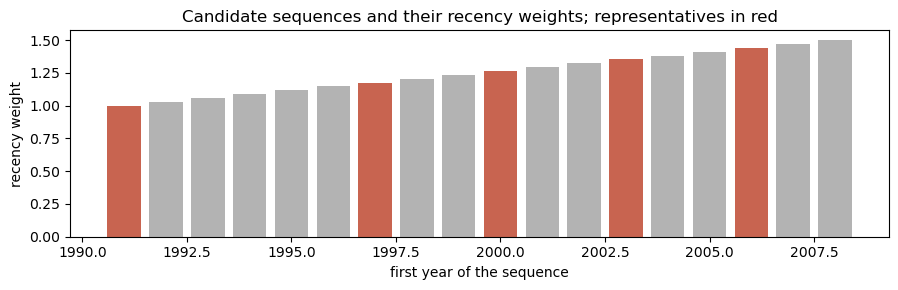

In [9]:
# Overlap: how many weather years do the representatives share?
labels = [str(seq) for seq in representativeSequences]
print("Shared weather years between the representative sequences (overlap):")
display(
    pd.DataFrame(
        [[len(set(a) & set(b)) for b in representativeSequences] for a in representativeSequences],
        index=labels,
        columns=labels,
    )
)

fig, ax = plt.subplots(figsize=(9, 3))
starts = [seq[0] for seq in candidateSequences]
colors = ["#C86450" if seq in representativeSequences else "0.7" for seq in candidateSequences]
ax.bar(starts, [baseWeight[seq] for seq in candidateSequences], color=colors)
ax.set_xlabel("first year of the sequence")
ax.set_ylabel("recency weight")
ax.set_title("Candidate sequences and their recency weights; representatives in red")
plt.tight_layout()
plt.show()

### The representative sequences as tree nodes

Each column is one stage-2 node: its weather sequence applied to 2033–2035, with the demand of
those years. Rows: total demand of both regions, wind and PV capacity factors (mean of both
regions), and the residual load (demand minus the output of the reference fleet used for the
selection). Daily means (thin) and 7-day means (thick); the rows share their y-axis, so the nodes
can be compared directly. The dotted lines separate the three years.

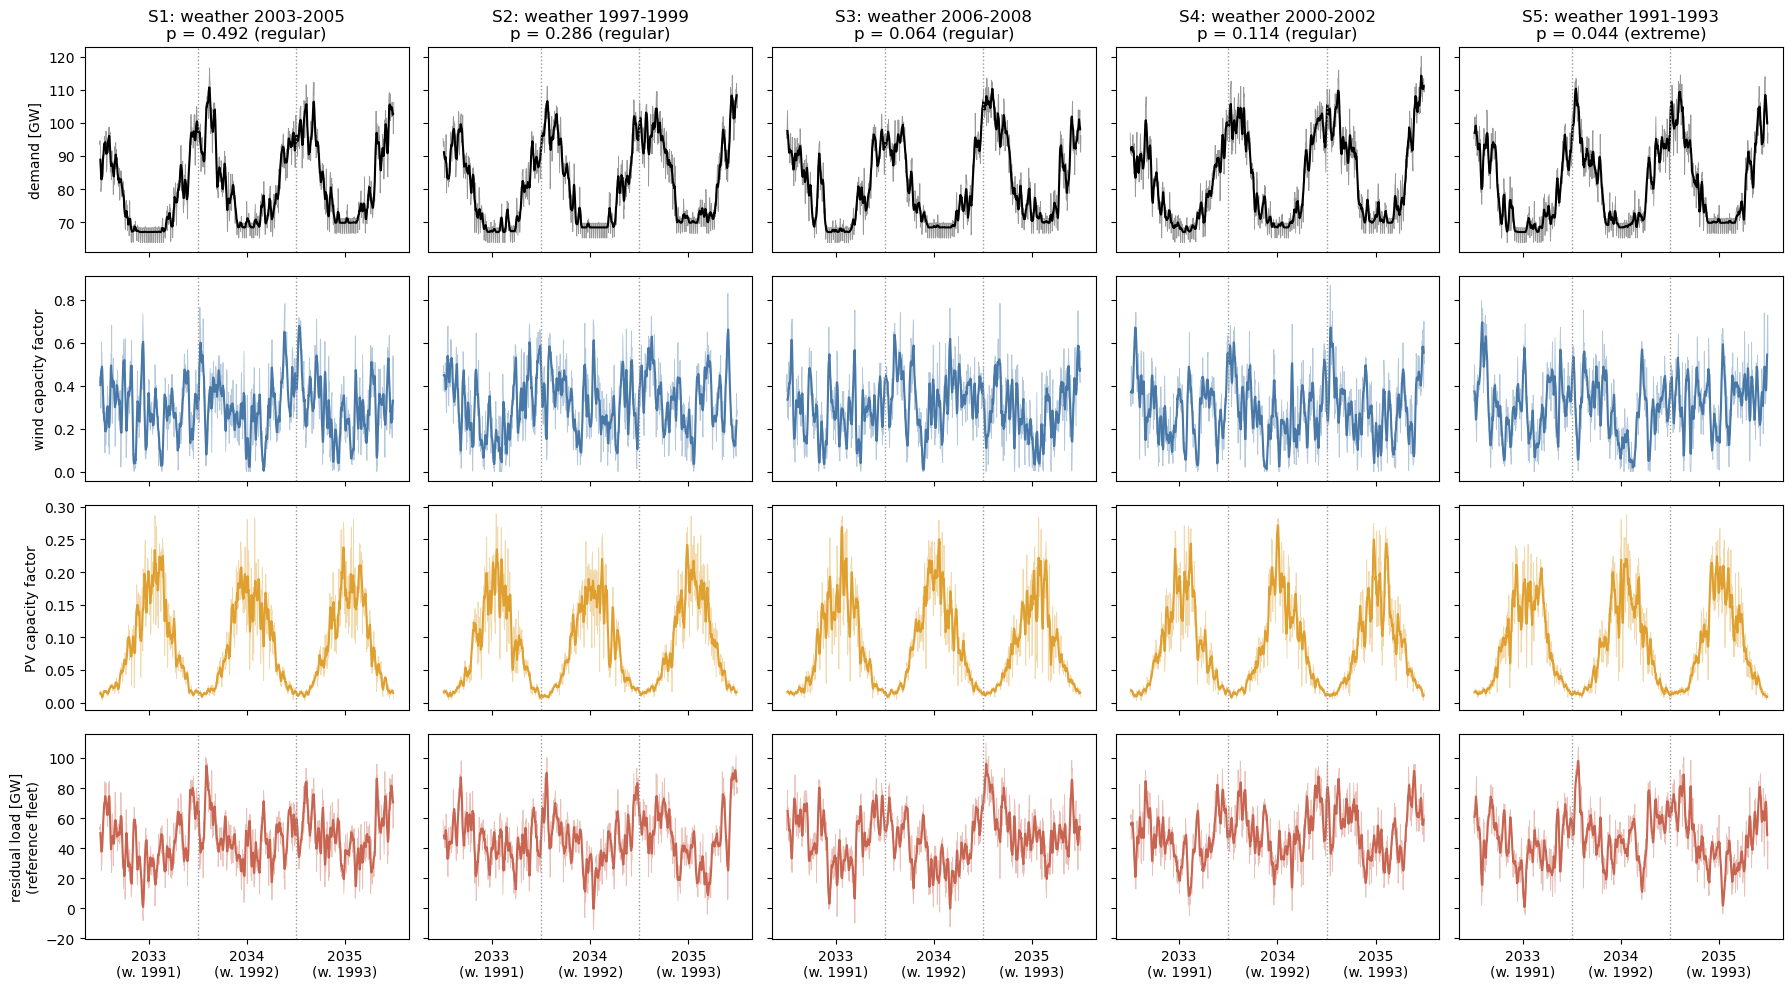

In [10]:
stageTwoYears = [WEATHER_IP_YEARS[ip] for ip in WEATHER_STAGES[1]]
dayAxis = np.arange(365 * len(stageTwoYears))

fig, axes = plt.subplots(4, len(representativeSequences), figsize=(3.6 * len(representativeSequences), 10),
                         sharey="row", sharex=True)
for col, (sequence, probability) in enumerate(zip(representativeSequences, sequenceProbabilities)):
    # the node's data over the stage: year i of the stage gets weather year i of the sequence
    demand, wind, pv, residual = [], [], [], []
    for ipYear, weatherYear in zip(stageTwoYears, sequence):
        d = demandFromParts(STRUCTURE[ipYear], weatherYear)
        w = weatherYears[weatherYear]
        demand.append(d.sum(axis=1).to_numpy())
        wind.append(w[["wind_north", "wind_south"]].mean(axis=1).to_numpy())
        pv.append(w[["pv_north", "pv_south"]].mean(axis=1).to_numpy())
        residual.append(sum(
            d[r].to_numpy()
            - REFERENCE_FLEET["wind"][r] * w[f"wind_{r}"].to_numpy()
            - REFERENCE_FLEET["pv"][r] * w[f"pv_{r}"].to_numpy()
            for r in WEATHER_REGIONS
        ))
    for row, (series, color) in enumerate([(demand, "k"), (wind, "#4878A8"), (pv, "#E0A030"), (residual, "#C86450")]):
        daily = np.concatenate(series).reshape(-1, 24).mean(axis=1)
        axes[row, col].plot(dayAxis, daily, color=color, lw=0.6, alpha=0.4)
        axes[row, col].plot(dayAxis, pd.Series(daily).rolling(7, center=True).mean(), color=color, lw=1.5)
        for boundary in (365, 730):
            axes[row, col].axvline(boundary, color="0.6", ls=":", lw=1)
    kind = "extreme" if sequence == extremeSequence else "regular"
    axes[0, col].set_title(f"S{col + 1}: weather {sequence[0]}-{sequence[-1]}\np = {probability:.3f} ({kind})")
    axes[3, col].set_xticks([182, 547, 912])
    axes[3, col].set_xticklabels([f"{y}\n(w. {w})" for y, w in zip(stageTwoYears, sequence)])
axes[0, 0].set_ylabel("demand [GW]")
axes[1, 0].set_ylabel("wind capacity factor")
axes[2, 0].set_ylabel("PV capacity factor")
axes[3, 0].set_ylabel("residual load [GW]\n(reference fleet)")
plt.tight_layout()
plt.show()

**What the figure shows.** The nodes share the seasonal shape; they differ in the winters. PV
hardly differs between the nodes. The differences are in wind and in the winter demand, and they
add up in the residual load:

* S1 and the extreme sequence S5 have the sharpest single residual-load peaks (about 95–100 GW
  around the turn of 2033/34); S3 has its peak at the turn of 2034/35.
* S4 (2000–2002) has no single highest peak, but a high residual load over long stretches of the
  winters 2034 and 2035, with the highest demand at the end of 2035.
* S2 (1997–1999) is the windiest sequence and has the lowest residual load.

The extreme sequence is chosen by its worst *week*, so it stands for a short, deep shortage
(capacity), not for a long one (energy). The next section shows that this matters.

## 4. The scenario tree: one node per weather sequence

* **Root (stage 1, 2030–2032):** **one** weather sequence, `ROOT_SEQUENCE` (here the most
  probable representative). The first-stage decisions are made knowing this weather (see
  section 3 of the markdown note). In the rolling-horizon application, the weather of the first
  stage will instead come from the Pan-European Climate Database.
* **Stage 2 (2033–2035):** one node per representative sequence, with the sequence's
  probability. Year *i* of the stage gets weather year *i* of the node's sequence.
* **Uncertain values of a node**, per investment period: `Wind.operationRateMax`,
  `PV.operationRateMax` and `Demand.operationRateFix` (structure + that weather year). The weather
  of a node is therefore known when that node's decisions are made.
* **One weather year per investment period** (`numberOfTimeSteps = 8760`). FINE's storage handling
  fits as it is: the state of charge is cyclic over each year, and the battery may shift energy
  within the year (no `isPeriodicalStorage` needed).
* **Aggregation:** 12 typical days per investment period plus the day of peak demand (a single
  extreme criterion because of a FINE bug with several, `fine/energySystemModel.py:1178`).
* **Load shedding** with a value of lost load of 10,000 EUR/MWh keeps every scenario feasible.

In [11]:
# Two helpers that are used for the tree model here and for the evaluation model in section 6.
CONNECTIONS = ["north_south", "south_north"]


def capacityFactors(kind, year):
    """Hourly wind or PV capacity factors of one weather year, per region."""
    return pd.DataFrame({r: weatherYears[year][f"{kind}_{r}"].to_numpy() for r in WEATHER_REGIONS})


def addWeatherComponents(model, windCF, pvCF, demandSeries, fixes=None):
    """Components of the example. ``fixes`` = {component: {year: Series}} fixes the commissioning."""

    def fixed(comp, index):
        if fixes is None:
            return {}
        return {
            "commissioningFix": {
                yr: fixes.get(comp, {}).get(yr, pd.Series(dtype=float)).reindex(index, fill_value=0.0)
                for yr in model.investmentPeriodNames
            }
        }

    model.add(fn.Source(model, name="Wind", commodity="electricity", hasCapacityVariable=True,
                        operationRateMax=windCF, capacityMax=pd.Series({"north": 90.0, "south": 50.0}),
                        investPerCapacity=1.3, opexPerCapacity=1.3 * 0.02, interestRate=0.05,
                        economicLifetime=25, technicalLifetime=25, **fixed("Wind", WEATHER_REGIONS)))
    model.add(fn.Source(model, name="PV", commodity="electricity", hasCapacityVariable=True,
                        operationRateMax=pvCF, capacityMax=pd.Series({"north": 60.0, "south": 90.0}),
                        investPerCapacity=0.55, opexPerCapacity=0.55 * 0.015, interestRate=0.05,
                        economicLifetime=25, technicalLifetime=25, **fixed("PV", WEATHER_REGIONS)))
    model.add(fn.Source(model, name="GasPurchase", commodity="naturalGas",
                        hasCapacityVariable=False, commodityCost=50e-6))  # 50 EUR/MWh
    model.add(fn.Source(model, name="LoadShedding", commodity="electricity",
                        hasCapacityVariable=False, commodityCost=10e-3))  # VoLL 10,000 EUR/MWh
    model.add(fn.Conversion(model, name="GasTurbine", physicalUnit="GW_el",
                            commodityConversionFactors={"naturalGas": -1 / 0.40, "electricity": 1.0},
                            hasCapacityVariable=True, investPerCapacity=0.50,
                            opexPerCapacity=0.50 * 0.03, interestRate=0.05, economicLifetime=30,
                            technicalLifetime=30, **fixed("GasTurbine", WEATHER_REGIONS)))
    # one weather year per investment period: the state of charge is cyclic over that year
    # (FINE's default), seasonal shifting within the year is allowed
    model.add(fn.Storage(model, name="Battery", commodity="electricity", hasCapacityVariable=True,
                         chargeRate=0.25, dischargeRate=0.25, chargeEfficiency=0.95,
                         dischargeEfficiency=0.95, investPerCapacity=0.20,
                         opexPerCapacity=0.20 * 0.01, interestRate=0.05, economicLifetime=15,
                         technicalLifetime=15, **fixed("Battery", WEATHER_REGIONS)))
    model.add(fn.Transmission(model, name="Grid", commodity="electricity", hasCapacityVariable=True,
                              distances=pd.DataFrame([[0, 300], [300, 0]], index=WEATHER_REGIONS,
                                                     columns=WEATHER_REGIONS),
                              losses=0.00005, investPerCapacity=0.0012, interestRate=0.05,
                              economicLifetime=40, technicalLifetime=40,
                              **fixed("Grid", CONNECTIONS)))
    model.add(fn.Sink(model, name="Demand", commodity="electricity", hasCapacityVariable=False,
                      operationRateFix=demandSeries))

In [12]:
# Base model: one weather year (8760 h) per investment period. Its weather-driven data are
# placeholders; every node of the tree overwrites them.
baseModel = fn.EnergySystemModel(
    locations=set(WEATHER_REGIONS),
    commodities={"electricity", "naturalGas"},
    numberOfTimeSteps=HOURS,
    commodityUnitsDict={"electricity": "GW_el", "naturalGas": "GW_CH4"},
    hoursPerTimeStep=1,
    costUnit="1e9 Euro",
    startYear=WEATHER_IP_YEARS[0],
    numberOfInvestmentPeriods=len(WEATHER_IP_YEARS),
    investmentPeriodInterval=1,
    lengthUnit="km",
    verboseLogLevel=2,
)
placeholderYear = CANDIDATE_YEARS[0]
addWeatherComponents(
    baseModel,
    windCF=capacityFactors("wind", placeholderYear),
    pvCF=capacityFactors("pv", placeholderYear),
    demandSeries=demandFromParts(STRUCTURE[2030], placeholderYear),
)

# The tree: the root (stage 1) holds ROOT_SEQUENCE, stage 2 one node per representative.
# Year i of a stage gets weather year i of the node's sequence.
ROOT_SEQUENCE = representativeSequences[int(np.argmax(sequenceProbabilities))]
nodes = [("root", None, 1.0, 0, ROOT_SEQUENCE)] + [
    (f"S{k}_{seq[0]}-{seq[-1]}", "root", p, 1, seq)
    for k, (seq, p) in enumerate(zip(representativeSequences, sequenceProbabilities), start=1)
]
weatherTree = {}
for name, parent, probability, stage, sequence in nodes:
    weather = {WEATHER_IP_YEARS[ip]: year for ip, year in zip(WEATHER_STAGES[stage], sequence)}
    weatherTree[name] = {
        "parent": parent,
        "probability": probability,
        "values": {
            "Demand": {"operationRateFix": {yr: demandFromParts(STRUCTURE[yr], w) for yr, w in weather.items()}},
            "Wind": {"operationRateMax": {yr: capacityFactors("wind", w) for yr, w in weather.items()}},
            "PV": {"operationRateMax": {yr: capacityFactors("pv", w) for yr, w in weather.items()}},
        },
    }
print("root sequence (weather of 2030-2032):", ROOT_SEQUENCE)
print(mssp.ScenarioTree(weatherTree).describe())

# 12 typical days per investment period plus the day of peak demand
WEATHER_AGGREGATION = {
    "n_clusters": 12,
    "period_duration": 24,
    "segments": None,
    "extremes": tsam.ExtremeConfig(method="append", max_value=["Demand_operationRateFix_north"]),
}

start = time.time()
resultsWeather = mssp.optimizeMultiStageStochastic(
    baseModel,
    weatherTree,
    stageInvestmentPeriods=WEATHER_STAGES,
    method="ef",
    solver="gurobi",
    timeSeriesAggregation=True,
    temporalAggregationSpecs=WEATHER_AGGREGATION,
)
print(f"\nsolved in {time.time() - start:.1f} s, expected NPV {resultsWeather.objectiveValue:.3f} 1e9 Euro")

root sequence (weather of 2030-2032): (2003, 2004, 2005)
Scenario tree with 2 stages, 6 nodes and 5 scenarios:
  stage  1  root                 parent=-                    p=1.0000  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  2  S1_2003-2005         parent=root                 p=0.4915  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  2  S2_1997-1999         parent=root                 p=0.2863  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  2  S3_2006-2008         parent=root                 p=0.0641  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  2  S4_2000-2002         parent=root                 p=0.1137  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  2  S5_1991-1993         parent=root                 p=0.0444  values=['Demand.operationRateFix', 'PV.operation


solved in 77.8 s, expected NPV 274.829 1e9 Euro


## 5. First-stage decisions, and a benchmark without weather branching

The first stage covers 2030–2032, with investment allowed in every year. As a benchmark, the same
model is solved **without weather branching**: stage 2 has a single node with the root's sequence.
The difference in the first stage shows what hedging against the weather of stage 2 changes.

Without lead times, a stage-2 node can still build the capacity it needs in its own years, knowing
its weather, so the first stage has little reason to hedge. With lead times, capacity decided in
stage 2 arrives later, and the first stage has to anticipate the stage-2 weather more.

In [13]:
# Benchmark without weather branching: stage 2 is a single node with the root's sequence
rootSequenceNode = next(name for name, _, _, _, seq in nodes[1:] if seq == ROOT_SEQUENCE)
noBranchingTree = {
    "root": weatherTree["root"],
    rootSequenceNode: {**weatherTree[rootSequenceNode], "probability": 1.0},
}
start = time.time()
resultsNoWeatherBranching = mssp.optimizeMultiStageStochastic(
    baseModel,
    noBranchingTree,
    stageInvestmentPeriods=WEATHER_STAGES,
    method="ef",
    solver="gurobi",
    timeSeriesAggregation=True,
    temporalAggregationSpecs=WEATHER_AGGREGATION,
)
print(f"weather not branched (stage 2 uses {ROOT_SEQUENCE}): solved in {time.time() - start:.1f} s, "
      f"expected NPV {resultsNoWeatherBranching.objectiveValue:.3f} 1e9 Euro")

# First-stage decisions of ALL first-stage investment periods, read from a scenario's commis_
# variables (the module's firstStageDecisions() only returns the first investment period).
strategies = {
    f"weather branched ({len(representativeSequences)} sequences)": resultsWeather,
    "weather not branched": resultsNoWeatherBranching,
}
firstStage = {}
for label, results in strategies.items():
    model = next(iter(results.scenarioModels.values()))  # equal in all scenarios
    decisions = {}
    for mdl in model.componentModelingDict.values():
        variable = getattr(model.pyM, "commis_" + mdl.abbrvName, None)
        if variable is None:
            continue
        for loc, comp, ip in variable:
            if ip in WEATHER_STAGES[0]:
                decisions[(comp, loc, WEATHER_IP_YEARS[ip])] = variable[loc, comp, ip].value
    firstStage[label] = pd.Series(decisions)

firstStageComparison = pd.DataFrame(firstStage)
firstStageComparison = firstStageComparison[firstStageComparison.abs().max(axis=1) > 1e-6].round(2)
firstStageComparison.index.names = ["component", "location", "commissioned"]
firstStageComparison

[   77.75] Initializing SPBase


weather not branched (stage 2 uses (2003, 2004, 2005)): solved in 12.8 s, expected NPV 274.443 1e9 Euro


weather branched (5 sequences)  \
component  location    commissioned                                   
Wind       north       2030                                   90.00   
           south       2030                                   50.00   
PV         north       2030                                   23.35   
                       2031                                   14.92   
           south       2030                                   90.00   
GasTurbine south       2030                                   27.35   
                       2031                                    6.21   
                       2032                                    0.00   
           north       2030                                   27.24   
                       2031                                   16.43   
                       2032                                    0.25   
Battery    south       2030                                   27.27   
           north       2030                                    5.86   
                       2031                                   17.71   
Grid       north_south 2030                                   10.62   
           south_north 2030                                   10.62   

                                     weather not branched  
component  location    commissioned                        
Wind       north       2030                         90.00  
           south       2030                         50.00  
PV         north       2030                         23.53  
                       2031                         15.32  
           south       2030                         90.00  
GasTurbine south       2030                         27.40  
                       2031                          6.04  
                       2032                          0.26  
           north       2030                         27.11  
                       2031                         16.45  
                       2032                          0.00  
Battery    south       2030                         27.72  
           north       2030                          5.75  
                       2031                         18.27  
Grid       north_south 2030                         10.51  
           south_north 2030                         10.51

## 6. Out-of-sample evaluation of the first stage

The first-stage decisions know the root's weather sequence. How do they perform when 2030–2032
bring different weather? For each sampled **real** sequence from the record (a complete window):

1. the first-stage commissioning is fixed (`commissioningFix`),
2. 2030–2032 are operated with the root node's structural demand and the sampled weather,
3. the cost and the unserved demand (load shedding) are recorded.

This runs without the rolling-horizon wrapper. To keep the notebook fast, the evaluation uses 48
typical days plus the peak-demand day per year; set `EVALUATION_TYPICAL_DAYS = None` for full
hourly resolution (much slower; in an earlier run, the 48-day evaluation underestimated the
unserved demand by up to a factor of 2).

In [14]:
EVALUATION_TYPICAL_DAYS = 48  # None = full hourly resolution (much slower)
EVALUATION_SAMPLES = 4
FIRST_STAGE_YEARS = [WEATHER_IP_YEARS[ip] for ip in WEATHER_STAGES[0]]

# Realized weather: real, complete sequences from the whole record
rng = np.random.default_rng(7)
realizedSequences = [completeWindows[i] for i in rng.choice(len(completeWindows), EVALUATION_SAMPLES, replace=False)]

rows = []
start = time.time()
for label, decisions in firstStage.items():
    # first-stage commissioning as {component: {year: Series per location}}
    fixes = {}
    for (comp, loc, year), value in decisions.items():
        fixes.setdefault(comp, {}).setdefault(year, {})[loc] = max(value, 0.0)
    fixes = {comp: {yr: pd.Series(v) for yr, v in perYear.items()} for comp, perYear in fixes.items()}

    for sequence in realizedSequences:
        # operate the first stage with fixed investments under the realized weather
        evaluationModel = fn.EnergySystemModel(
            locations=set(WEATHER_REGIONS),
            commodities={"electricity", "naturalGas"},
            numberOfTimeSteps=HOURS,
            commodityUnitsDict={"electricity": "GW_el", "naturalGas": "GW_CH4"},
            hoursPerTimeStep=1,
            costUnit="1e9 Euro",
            startYear=FIRST_STAGE_YEARS[0],
            numberOfInvestmentPeriods=len(FIRST_STAGE_YEARS),
            investmentPeriodInterval=1,
            lengthUnit="km",
            verboseLogLevel=2,
        )
        realized = dict(zip(FIRST_STAGE_YEARS, sequence))
        addWeatherComponents(
            evaluationModel,
            windCF={yr: capacityFactors("wind", w) for yr, w in realized.items()},
            pvCF={yr: capacityFactors("pv", w) for yr, w in realized.items()},
            demandSeries={yr: demandFromParts(STRUCTURE[yr], w) for yr, w in realized.items()},
            fixes=fixes,
        )
        aggregate = EVALUATION_TYPICAL_DAYS is not None
        if aggregate:
            evaluationModel.aggregateTemporally(**{**WEATHER_AGGREGATION, "n_clusters": EVALUATION_TYPICAL_DAYS})
        evaluationModel.optimize(solver="gurobi", timeSeriesAggregation=aggregate)

        # unserved demand = load shedding, weighted with the occurrences of the typical days
        op = evaluationModel.pyM.op_srcSnk
        unserved = sum(
            op[key].value * evaluationModel.periodOccurrences[key[2]][key[3]]
            for key in op
            if key[1] == "LoadShedding"
        )
        rows.append(
            {"first stage from": label, "realized weather": str(sequence),
             "cost [1e9 EUR]": evaluationModel.objectiveValue, "unserved demand [GWh]": unserved}
        )
print(f"{len(rows)} evaluation runs in {time.time() - start:.1f} s")

evaluation = pd.DataFrame(rows)
display(evaluation.round(2))
evaluation.groupby("first stage from")[["cost [1e9 EUR]", "unserved demand [GWh]"]].mean().round(2)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter LogToConsole to value 0


Set parameter OutputFlag to value 1


...

Set parameter LogFile to value ""


Set parameter LogToConsole to value 0


8 evaluation runs in 140.0 s


,first stage from,realized weather,cost [1e9 EUR],unserved demand [GWh]
0,weather branched (5 sequences),"(2005, 2006, 2007)",165.27,2648.73
1,weather branched (5 sequences),"(2001, 2002, 2003)",195.87,4913.69
2,weather branched (5 sequences),"(2007, 2008, 2009)",140.89,487.32
3,weather branched (5 sequences),"(2002, 2003, 2004)",187.88,4603.11
4,weather not branched,"(2005, 2006, 2007)",165.57,2678.66
5,weather not branched,"(2001, 2002, 2003)",196.23,4949.16
6,weather not branched,"(2007, 2008, 2009)",140.97,495.14
7,weather not branched,"(2002, 2003, 2004)",188.52,4671.84


,cost [1e9 EUR],unserved demand [GWh]
first stage from,,
weather branched (5 sequences),172.48,3163.21
weather not branched,172.82,3198.70


## 7. Stage-2 decisions per node

Every stage-2 node decides its investments knowing its own weather sequence. The table shows the
total commissioning per node over 2033–2035 (summed over regions; the grid counted once per line)
and the node's probability. The nodes differ only in their weather.

In [15]:
# Total commissioning per stage-2 node and component, summed over regions and stage-2 years
totals = {}
for scenario, model in resultsWeather.scenarioModels.items():
    for mdl in model.componentModelingDict.values():
        variable = getattr(model.pyM, "commis_" + mdl.abbrvName, None)
        if variable is None:
            continue
        for loc, comp, ip in variable:
            if ip in WEATHER_STAGES[1] and not loc.endswith("_north"):  # count a grid line once
                totals[(scenario, comp)] = totals.get((scenario, comp), 0.0) + variable[loc, comp, ip].value

stageTwo = pd.Series(totals).unstack().round(2)
stageTwo.index.name = "stage-2 node"
stageTwo.insert(0, "probability", [round(weatherTree[node]["probability"], 3) for node in stageTwo.index])
stageTwo

,probability,Battery,GasTurbine,Grid,PV,Wind
stage-2 node,,,,,,
S1_2003-2005,0.492,0.0,13.43,0.0,11.48,0.0
S2_1997-1999,0.286,0.0,16.13,0.0,0.00,0.0
S3_2006-2008,0.064,0.0,13.16,0.0,10.00,0.0
S4_2000-2002,0.114,0.0,8.53,0.0,2.12,0.0
S5_1991-1993,0.044,0.0,18.19,0.0,3.89,0.0


### Generation per node

How each stage-2 node runs its system over 2033–2035: daily mean generation of both regions by
technology (stacked), with the demand as a line, and the total generation per node over the
stage. FINE returns the operation for all 8760 hours of every year, also with time series
aggregation: every day then shows the profile of the typical day it was assigned to, so the
day-to-day variation within a year comes from only 13 typical days. Battery charging and grid
flows are not shown (they cancel out in the system total apart from losses).

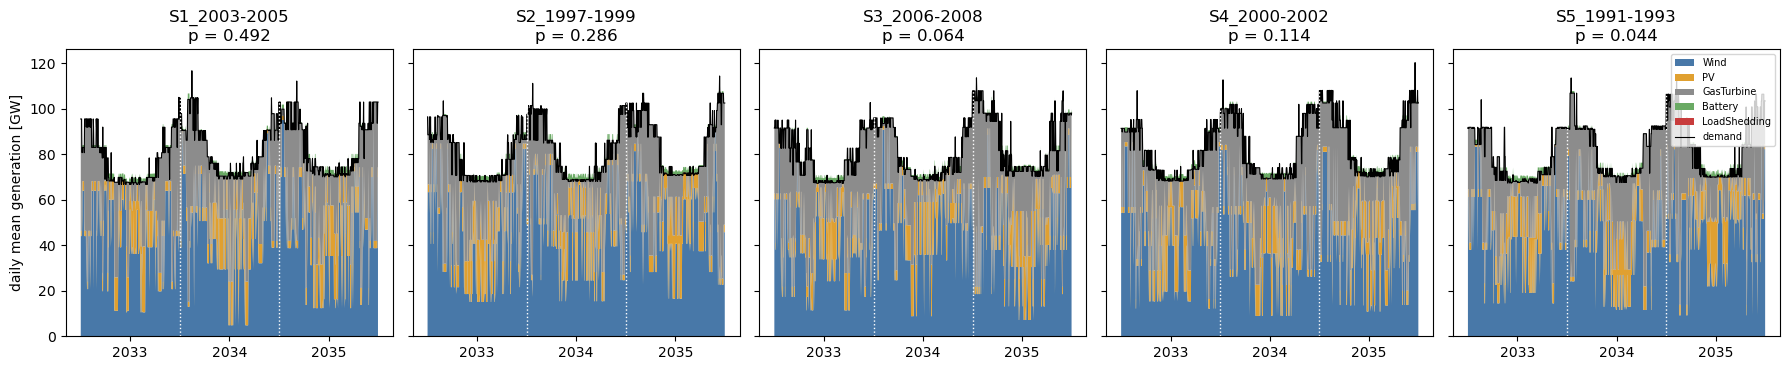

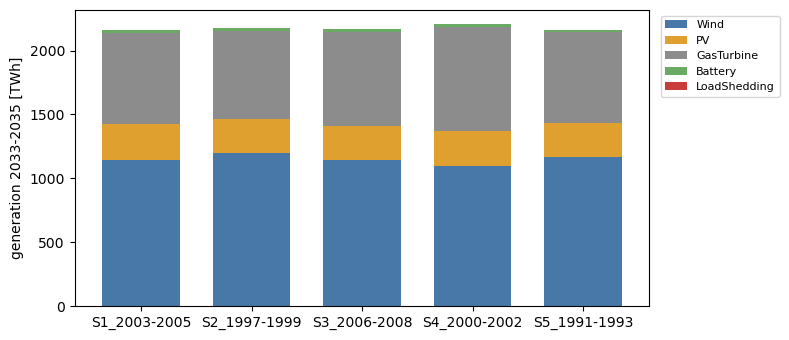

,Wind,PV,GasTurbine,Battery,LoadShedding
S1_2003-2005,1142.7,279.2,711.9,25.3,0.0
S2_1997-1999,1199.2,263.0,689.3,25.9,0.0
S3_2006-2008,1142.0,265.3,736.4,25.0,0.0
S4_2000-2002,1098.6,270.0,816.8,21.3,0.0
S5_1991-1993,1168.6,266.4,706.1,22.6,0.0


In [16]:
technologies = {  # name: (modeling class, optimal-value name, color)
    "Wind": ("SourceSinkModel", "operationVariablesOptimum", "#4878A8"),
    "PV": ("SourceSinkModel", "operationVariablesOptimum", "#E0A030"),
    "GasTurbine": ("ConversionModel", "operationVariablesOptimum", "#8C8C8C"),
    "Battery": ("StorageModel", "dischargeOperationVariablesOptimum", "#6AAA64"),
    "LoadShedding": ("SourceSinkModel", "operationVariablesOptimum", "#C83C3C"),
}
nodeNames = [name for name, parent, _, _, _ in nodes if parent is not None]
dayAxis = np.arange(365 * len(stageTwoYears))

fig, axes = plt.subplots(1, len(nodeNames), figsize=(3.6 * len(nodeNames), 3.8), sharey=True)
totals = {}
for ax, node in zip(axes, nodeNames):
    model = resultsWeather.scenarioModels[node]
    daily, totals[node] = {}, {}
    for tech, (modelingClass, valueName, _) in technologies.items():
        hourly = np.concatenate([
            model.componentModelingDict[modelingClass]
            .getOptimalValues(valueName, ip=year)["values"]
            .loc[tech].sum(axis=0).to_numpy()  # sum over both regions, GWh per hour = GW
            for year in stageTwoYears
        ])
        daily[tech] = hourly.reshape(-1, 24).mean(axis=1)
        totals[node][tech] = hourly.sum() / 1000  # TWh over the stage
    demandHourly = np.concatenate([
        model.componentModelingDict["SourceSinkModel"]
        .getOptimalValues("operationVariablesOptimum", ip=year)["values"]
        .loc["Demand"].sum(axis=0).to_numpy()
        for year in stageTwoYears
    ])
    ax.stackplot(dayAxis, *daily.values(), colors=[c for _, _, c in technologies.values()],
                 labels=list(technologies), linewidth=0)
    ax.plot(dayAxis, demandHourly.reshape(-1, 24).mean(axis=1), color="k", lw=0.8, label="demand")
    for boundary in (365, 730):
        ax.axvline(boundary, color="white", ls=":", lw=1)
    ax.set_title(f"{node}\np = {weatherTree[node]['probability']:.3f}")
    ax.set_xticks([182, 547, 912])
    ax.set_xticklabels(stageTwoYears)
axes[0].set_ylabel("daily mean generation [GW]")
axes[-1].legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

totalTable = pd.DataFrame(totals).T
fig, ax = plt.subplots(figsize=(8, 3.5))
totalTable.plot.bar(stacked=True, ax=ax, color=[c for _, _, c in technologies.values()], width=0.7)
ax.set_ylabel("generation 2033-2035 [TWh]")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()
totalTable.round(1)

**What the results show.** Total generation is similar in all nodes (about 2,160–2,200 TWh over
the three years), but the mix depends on the weather:

| node | wind | PV | gas turbines | battery | load shedding |
|---|---|---|---|---|---|
| S1 (2003–2005) | 1,143 | 279 | 712 | 25 | 0 |
| S2 (1997–1999) | 1,199 | 263 | 689 | 26 | 0 |
| S3 (2006–2008) | 1,142 | 265 | 736 | 25 | 0 |
| S4 (2000–2002) | 1,099 | 270 | 817 | 21 | 0 |
| S5 (1991–1993, extreme) | 1,169 | 266 | 706 | 23 | 0 |

(TWh, 2033–2035.) Gas-turbine generation ranges from 689 to 817 TWh, i.e. from −6 % to +12 %
around the mean; wind varies by about ±4 %.

* **S4 needs the most gas-turbine energy** (817 TWh): long periods of high residual load (see the
  node figure). **The extreme sequence S5 is not the one that needs the most energy**: its
  shortage is short and deep, so it mainly needs gas-turbine *capacity* (it builds the most, see
  the table above). The extreme criterion therefore covers capacity adequacy, not long energy
  shortages; a second criterion (e.g. the worst month) would cover those, but needs the FINE
  bug in section 9 of the approach document fixed first.
* No node sheds load in-sample: without lead times, each stage-2 node builds what its own weather
  needs.
* The stripes in the stacked plot come from the time series aggregation: every day shows one of
  13 typical days per year.

Since the synthetic weather underestimates scarcity (section 2), these differences are probably
smaller than they would be with real data.

## 8. Takeaways

Results of this run (synthetic data, Gurobi, about 4 minutes in total):

* **The synthetic weather is too benign** (section 2): 4–10 % of the hours with wind CF < 0.1
  (real data: 35 %), mean PV CF 0.074–0.079 (real: 0.122), peak/mean demand 1.35 (real: 1.59). It
  underestimates scarcity; the method can be tested with it, but the numbers below are not
  results. Real multi-year data (PECD) are needed.
* **Edge effect.** With complete windows, 1991 and 2010 appear in 1 of the 18 sequences, 1992
  and 2009 in 2.
* **Selection** (a few seconds): 4 regular representatives, (2003, 2004, 2005) with probability 0.492,
  (1997, 1998, 1999) with 0.286, (2000, 2001, 2002) with 0.114 and (2006, 2007, 2008) with 0.064,
  plus the extreme sequence (1991, 1992, 1993) with 0.044. With the mild recency weighting, the
  old extreme sequence keeps a probability close to its unweighted share of 1/18 = 0.056. **The
  representatives do not overlap** (overlap table).
* **Representation quality** (tsam metrics, normalized to each feature's range):
  * weighted RMSE 0.027, i.e. a member deviates from its representative by about 3 % of the
    range on average; per cluster, between 0.021 and 0.030;
  * the worst-represented features are the persistence features (7- and 14-day rolling residual
    load, RMSE up to 0.046);
  * the loss shrinks only slowly with more representatives: weighted RMSE 0.034 with 2, 0.027
    with 5 and 0.021 with 9. The correlation error falls faster: 0.25 with 2, 0.14 with 5 and
    0.01 with 9.
  * The synthetic years are fairly similar to each other, so even a single representative is
    only a few percent off. Real data will show more spread.
* **Tree:** 5 stage-2 nodes, solved in 72 s; without weather branching (1 stage-2 node) in 13 s.
* **First stage: almost unchanged by weather branching.** For example, gas turbines in the north
  in 2030 are 27.2 GW with and 27.1 GW without weather branching. Without lead times, a stage-2
  node can build what it needs in its own years, knowing its weather (section 7: the node with
  the extreme sequence builds the most gas turbines, 18.2 GW), so the first stage has little
  reason to hedge. Lead times are expected to change this.
* **Weather changes the generation mix, not the total:** gas-turbine generation in 2033–2035
  ranges from 689 TWh (S2, windiest) to 817 TWh (S4, long periods of high residual load), wind
  from 1,099 to 1,199 TWh. The extreme sequence (chosen by its worst week) needs the most
  gas-turbine capacity, but not the most energy.
* **Out-of-sample**, the first-stage decisions are tuned to the root's sequence (2003, 2004, 2005).
  Under other real sequences, they leave a lot of demand unserved: on average 3,163 GWh with and
  3,199 GWh without weather branching; mean cost 172.5 vs. 172.8. In the rolling-horizon
  application, the first-stage weather comes from the PECD instead.

Limitations: synthetic data; no lead times; typical days per weather year; only 4 out-of-sample
sequences; see [`weather_sequences_approach.md`](weather_sequences_approach.md).